# Tech Challenge - Fase 2
## Otimização de Modelo de Diagnóstico com Algoritmo Genético

Neste notebook será implementado um Algoritmo Genético para otimizar os hiperparâmetros da Regressão Logística desenvolvida na Fase 1.

O objetivo é buscar configurações de hiperparâmetros com melhor desempenho utilizando os conceitos de população, fitness, seleção, crossover e mutação, comparando posteriormente os resultados com o modelo otimizado por GridSearchCV.

In [44]:
from pathlib import Path

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

SEMENTE = 42

random.seed(SEMENTE)
np.random.seed(SEMENTE)

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## Preparação dos dados

O mesmo conjunto de dados utilizado na Fase 1 é carregado novamente para garantir a comparabilidade dos resultados.

As colunas `id` e `Unnamed: 32` são removidas, pois não possuem valor preditivo. A variável alvo `diagnosis` é convertida para formato numérico:

- `0`: Benigno;
- `1`: Maligno.

A divisão entre treino e teste utiliza os mesmos parâmetros da Fase 1, mantendo `test_size=0.20`, estratificação da variável alvo e `random_state=42`.

In [45]:
# Carregamento e preparação dos dados

caminho_dados = Path("/app/data/data.csv")

dados = pd.read_csv(caminho_dados)

df = dados.copy()

df = df.drop(
    columns=[
        "id",
        "Unnamed: 32"
    ],
    errors="ignore"
)

mapa_diagnostico = {
    "B": 0,
    "M": 1
}

df["diagnosis"] = df["diagnosis"].map(
    mapa_diagnostico
)

df["diagnosis"] = df["diagnosis"].astype(int)

df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=SEMENTE
)

print("Dados preparados com sucesso.")
print(f"Total de registros: {len(df)}")
print(f"Treino: {len(X_train)}")
print(f"Teste: {len(X_test)}")
print(f"Quantidade de variáveis: {X.shape[1]}")

Dados preparados com sucesso.
Total de registros: 569
Treino: 455
Teste: 114
Quantidade de variáveis: 30


## Representação genética

Cada indivíduo do Algoritmo Genético representa uma possível configuração de hiperparâmetros da Regressão Logística.

O cromossomo é composto pelos genes `C`, `class_weight` e pela combinação `solver/penalty`. Esses genes serão modificados e combinados ao longo das gerações em busca de configurações com melhor desempenho.

In [46]:
# Espaço de busca dos hiperparâmetros

valores_c = [
    0.001,
    0.01,
    0.1,
    0.5,
    1.0,
    2.0,
    5.0,
    10.0,
    100.0
]

pesos_classe = [
    None,
    "balanced"
]

configuracoes_solver = [
    ("liblinear", "l1"),
    ("liblinear", "l2"),
    ("saga", "l1"),
    ("saga", "l2"),
    ("lbfgs", "l2")
]

print("Espaço genético definido.")
print(f"Valores possíveis de C: {len(valores_c)}")
print(f"Pesos de classe: {len(pesos_classe)}")
print(
    f"Combinações solver/penalty: "
    f"{len(configuracoes_solver)}"
)

Espaço genético definido.
Valores possíveis de C: 9
Pesos de classe: 2
Combinações solver/penalty: 5


In [47]:
def criar_individuo():
    indice_c = random.randrange(
        len(valores_c)
    )

    indice_peso = random.randrange(
        len(pesos_classe)
    )

    indice_solver = random.randrange(
        len(configuracoes_solver)
    )

    return [
        indice_c,
        indice_peso,
        indice_solver
    ]

In [48]:
def decodificar_individuo(individuo):

    indice_c = individuo[0]
    indice_peso = individuo[1]
    indice_solver = individuo[2]

    solver, penalty = (
        configuracoes_solver[
            indice_solver
        ]
    )

    parametros = {
        "C": valores_c[indice_c],
        "class_weight": pesos_classe[
            indice_peso
        ],
        "solver": solver,
        "penalty": penalty
    }

    return parametros

In [49]:
individuo_exemplo = criar_individuo()

parametros_exemplo = (
    decodificar_individuo(
        individuo_exemplo
    )
)

print(
    "Indivíduo:",
    individuo_exemplo
)

print(
    "Parâmetros:",
    parametros_exemplo
)

Indivíduo: [1, 0, 2]
Parâmetros: {'C': 0.01, 'class_weight': None, 'solver': 'saga', 'penalty': 'l1'}


In [50]:
def criar_populacao(
    tamanho_populacao
):
    populacao = [
        criar_individuo()
        for _ in range(
            tamanho_populacao
        )
    ]

    return populacao

In [51]:
populacao_teste = criar_populacao(
    tamanho_populacao=10
)

for indice, individuo in enumerate(
    populacao_teste,
    start=1
):
    print(
        f"Indivíduo {indice}:",
        individuo,
        "→",
        decodificar_individuo(
            individuo
        )
    )

Indivíduo 1: [3, 0, 1] → {'C': 0.5, 'class_weight': None, 'solver': 'liblinear', 'penalty': 'l2'}
Indivíduo 2: [1, 0, 4] → {'C': 0.01, 'class_weight': None, 'solver': 'lbfgs', 'penalty': 'l2'}
Indivíduo 3: [6, 0, 0] → {'C': 5.0, 'class_weight': None, 'solver': 'liblinear', 'penalty': 'l1'}
Indivíduo 4: [1, 0, 1] → {'C': 0.01, 'class_weight': None, 'solver': 'liblinear', 'penalty': 'l2'}
Indivíduo 5: [8, 0, 4] → {'C': 100.0, 'class_weight': None, 'solver': 'lbfgs', 'penalty': 'l2'}
Indivíduo 6: [3, 1, 1] → {'C': 0.5, 'class_weight': 'balanced', 'solver': 'liblinear', 'penalty': 'l2'}
Indivíduo 7: [7, 1, 0] → {'C': 10.0, 'class_weight': 'balanced', 'solver': 'liblinear', 'penalty': 'l1'}
Indivíduo 8: [2, 1, 2] → {'C': 0.1, 'class_weight': 'balanced', 'solver': 'saga', 'penalty': 'l1'}
Indivíduo 9: [4, 0, 1] → {'C': 1.0, 'class_weight': None, 'solver': 'liblinear', 'penalty': 'l2'}
Indivíduo 10: [5, 0, 0] → {'C': 2.0, 'class_weight': None, 'solver': 'liblinear', 'penalty': 'l1'}


## Função de aptidão (Fitness)

A qualidade de cada indivíduo será medida por meio de validação cruzada estratificada com 5 folds utilizando somente os dados de treinamento.

A função fitness considera Recall, F1-score e ROC-AUC. O Recall recebe maior peso devido à importância de reduzir falsos negativos em casos malignos.

A função utilizada é:

**Fitness = 0,50 × Recall + 0,30 × F1-score + 0,20 × ROC-AUC**

In [52]:
validacao_cruzada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMENTE
)

print("Validação cruzada configurada com 5 folds.")

Validação cruzada configurada com 5 folds.


In [53]:
def calcular_fitness(individuo):

    parametros = decodificar_individuo(
        individuo
    )

    modelo = Pipeline([
        (
            "padronizacao",
            StandardScaler()
        ),
        (
            "modelo",
            LogisticRegression(
                C=parametros["C"],
                class_weight=parametros[
                    "class_weight"
                ],
                solver=parametros["solver"],
                penalty=parametros["penalty"],
                max_iter=5000,
                random_state=SEMENTE
            )
        )
    ])

    resultados = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=validacao_cruzada,
        scoring={
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    recall_medio = np.mean(
        resultados["test_recall"]
    )

    f1_medio = np.mean(
        resultados["test_f1"]
    )

    roc_auc_medio = np.mean(
        resultados["test_roc_auc"]
    )

    fitness = (
        0.50 * recall_medio
        + 0.30 * f1_medio
        + 0.20 * roc_auc_medio
    )

    return {
        "fitness": fitness,
        "recall": recall_medio,
        "f1": f1_medio,
        "roc_auc": roc_auc_medio
    }

In [54]:
individuo_teste = criar_individuo()

resultado_teste = calcular_fitness(
    individuo_teste
)

print(
    "Indivíduo:",
    individuo_teste
)

print(
    "Parâmetros:",
    decodificar_individuo(
        individuo_teste
    )
)

print(
    f"Fitness: "
    f"{resultado_teste['fitness']:.4f}"
)

print(
    f"Recall: "
    f"{resultado_teste['recall']:.4f}"
)

print(
    f"F1-score: "
    f"{resultado_teste['f1']:.4f}"
)

print(
    f"ROC-AUC: "
    f"{resultado_teste['roc_auc']:.4f}"
)

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

Indivíduo: [6, 0, 2]
Parâmetros: {'C': 5.0, 'class_weight': None, 'solver': 'saga', 'penalty': 'l1'}
Fitness: 0.9596
Recall: 0.9471
F1-score: 0.9582
ROC-AUC: 0.9929


In [55]:
def avaliar_populacao(populacao):

    resultados = []

    for individuo in populacao:

        metricas = calcular_fitness(
            individuo
        )

        resultados.append({
            "individuo": individuo,
            "fitness": metricas[
                "fitness"
            ],
            "recall": metricas[
                "recall"
            ],
            "f1": metricas[
                "f1"
            ],
            "roc_auc": metricas[
                "roc_auc"
            ]
        })

    resultados.sort(
        key=lambda x: x["fitness"],
        reverse=True
    )

    return resultados

In [56]:
resultados_populacao = (
    avaliar_populacao(
        populacao_teste
    )
)

for posicao, resultado in enumerate(
    resultados_populacao,
    start=1
):
    print(
        f"{posicao}º - "
        f"Fitness: "
        f"{resultado['fitness']:.4f} "
        f"| Individuo: "
        f"{resultado['individuo']}"
    )

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

1º - Fitness: 0.9679 | Individuo: [3, 1, 1]
2º - Fitness: 0.9649 | Individuo: [4, 0, 1]
3º - Fitness: 0.9644 | Individuo: [5, 0, 0]
4º - Fitness: 0.9617 | Individuo: [3, 0, 1]
5º - Fitness: 0.9593 | Individuo: [2, 1, 2]
6º - Fitness: 0.9588 | Individuo: [6, 0, 0]
7º - Fitness: 0.9560 | Individuo: [8, 0, 4]
8º - Fitness: 0.9555 | Individuo: [1, 0, 1]
9º - Fitness: 0.9517 | Individuo: [7, 1, 0]
10º - Fitness: 0.9076 | Individuo: [1, 0, 4]


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

In [57]:
melhor_resultado = resultados_populacao[0]
pior_resultado = resultados_populacao[-1]

print("=== MELHOR INDIVÍDUO ===")
print(
    decodificar_individuo(
        melhor_resultado["individuo"]
    )
)
print(
    f"Fitness: "
    f"{melhor_resultado['fitness']:.4f}"
)
print(
    f"Recall: "
    f"{melhor_resultado['recall']:.4f}"
)
print(
    f"F1: "
    f"{melhor_resultado['f1']:.4f}"
)
print(
    f"ROC-AUC: "
    f"{melhor_resultado['roc_auc']:.4f}"
)

print()

print("=== PIOR INDIVÍDUO ===")
print(
    decodificar_individuo(
        pior_resultado["individuo"]
    )
)
print(
    f"Fitness: "
    f"{pior_resultado['fitness']:.4f}"
)
print(
    f"Recall: "
    f"{pior_resultado['recall']:.4f}"
)
print(
    f"F1: "
    f"{pior_resultado['f1']:.4f}"
)
print(
    f"ROC-AUC: "
    f"{pior_resultado['roc_auc']:.4f}"
)

=== MELHOR INDIVÍDUO ===
{'C': 0.5, 'class_weight': 'balanced', 'solver': 'liblinear', 'penalty': 'l2'}
Fitness: 0.9679
Recall: 0.9588
F1: 0.9644
ROC-AUC: 0.9956

=== PIOR INDIVÍDUO ===
{'C': 0.01, 'class_weight': None, 'solver': 'lbfgs', 'penalty': 'l2'}
Fitness: 0.9076
Recall: 0.8647
F1: 0.9234
ROC-AUC: 0.9911


## Operadores genéticos

Após avaliar a população inicial, inicia-se o processo evolutivo.

Os indivíduos com maior fitness possuem maior probabilidade de serem selecionados como pais. O crossover combina características desses indivíduos para produzir novos descendentes, enquanto a mutação introduz alterações aleatórias para manter a diversidade da população.

Também será utilizado elitismo para preservar as melhores soluções entre as gerações.

In [58]:
def selecionar_pai(resultados_avaliados):

    individuos = [
        resultado["individuo"]
        for resultado in resultados_avaliados
    ]

    pesos = [
        resultado["fitness"]
        for resultado in resultados_avaliados
    ]

    pai = random.choices(
        individuos,
        weights=pesos,
        k=1
    )[0]

    return pai.copy()

In [59]:
def crossover_uniforme(
    pai1,
    pai2
):

    filho1 = pai1.copy()
    filho2 = pai2.copy()

    for indice in range(
        len(pai1)
    ):

        if random.random() < 0.5:

            filho1[indice] = (
                pai2[indice]
            )

            filho2[indice] = (
                pai1[indice]
            )

    return filho1, filho2

In [60]:
pai1 = selecionar_pai(
    resultados_populacao
)

pai2 = selecionar_pai(
    resultados_populacao
)

filho1, filho2 = (
    crossover_uniforme(
        pai1,
        pai2
    )
)

print("Pai 1:", pai1)
print("Pai 2:", pai2)

print()

print("Filho 1:", filho1)
print("Filho 2:", filho2)

Pai 1: [7, 1, 0]
Pai 2: [6, 0, 0]

Filho 1: [7, 1, 0]
Filho 2: [6, 0, 0]


In [61]:
limites_genes = [
    len(valores_c),
    len(pesos_classe),
    len(configuracoes_solver)
]


def aplicar_mutacao(
    individuo,
    taxa_mutacao
):

    individuo_mutado = (
        individuo.copy()
    )

    for indice_gene, limite in enumerate(
        limites_genes
    ):

        if (
            random.random()
            < taxa_mutacao
        ):

            valor_atual = (
                individuo_mutado[
                    indice_gene
                ]
            )

            valores_possiveis = [
                valor
                for valor in range(
                    limite
                )
                if valor != valor_atual
            ]

            novo_valor = (
                random.choice(
                    valores_possiveis
                )
            )

            individuo_mutado[
                indice_gene
            ] = novo_valor

    return individuo_mutado

In [62]:
filho_original = filho1.copy()

filho_mutado = aplicar_mutacao(
    filho1,
    taxa_mutacao=0.50
)

print(
    "Antes da mutação:",
    filho_original
)

print(
    "Depois da mutação:",
    filho_mutado
)

print()

print(
    "Parâmetros após mutação:"
)

print(
    decodificar_individuo(
        filho_mutado
    )
)

Antes da mutação: [7, 1, 0]
Depois da mutação: [7, 0, 0]

Parâmetros após mutação:
{'C': 10.0, 'class_weight': None, 'solver': 'liblinear', 'penalty': 'l1'}


In [63]:
def criar_nova_geracao(
    resultados_avaliados,
    tamanho_populacao,
    taxa_mutacao,
    elitismo=2
):

    nova_populacao = []

    # Preserva os melhores indivíduos
    for resultado in (
        resultados_avaliados[
            :elitismo
        ]
    ):

        nova_populacao.append(
            resultado[
                "individuo"
            ].copy()
        )

    # Produz os demais indivíduos
    while (
        len(nova_populacao)
        < tamanho_populacao
    ):

        pai1 = selecionar_pai(
            resultados_avaliados
        )

        pai2 = selecionar_pai(
            resultados_avaliados
        )

        filho1, filho2 = (
            crossover_uniforme(
                pai1,
                pai2
            )
        )

        filho1 = aplicar_mutacao(
            filho1,
            taxa_mutacao
        )

        filho2 = aplicar_mutacao(
            filho2,
            taxa_mutacao
        )

        nova_populacao.append(
            filho1
        )

        if (
            len(nova_populacao)
            < tamanho_populacao
        ):

            nova_populacao.append(
                filho2
            )

    return nova_populacao

In [64]:
nova_populacao = (
    criar_nova_geracao(
        resultados_populacao,
        tamanho_populacao=10,
        taxa_mutacao=0.10,
        elitismo=2
    )
)

resultados_nova_geracao = (
    avaliar_populacao(
        nova_populacao
    )
)

print(
    "Melhor fitness "
    "da população inicial:"
)

print(
    f"{resultados_populacao[0]['fitness']:.4f}"
)

print()

print(
    "Melhor fitness "
    "da nova geração:"
)

print(
    f"{resultados_nova_geracao[0]['fitness']:.4f}"
)

print()

print("Melhor indivíduo:")

print(
    resultados_nova_geracao[
        0
    ]["individuo"]
)

print()

print("Parâmetros:")

print(
    decodificar_individuo(
        resultados_nova_geracao[
            0
        ]["individuo"]
    )
)

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Melhor fitness da população inicial:
0.9679

Melhor fitness da nova geração:
0.9679

Melhor indivíduo:
[3, 1, 1]

Parâmetros:
{'C': 0.5, 'class_weight': 'balanced', 'solver': 'liblinear', 'penalty': 'l2'}


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

## Processo evolutivo

O ciclo de avaliação, seleção, crossover e mutação será repetido durante várias gerações.

Em cada geração serão registrados o melhor fitness, o fitness médio e a diversidade da população. Dessa forma, será possível acompanhar o processo de evolução das soluções ao longo do tempo.

In [65]:
import time
import json
import joblib

In [66]:
def avaliar_populacao_cache(
    populacao,
    cache_fitness
):

    resultados = []

    for individuo in populacao:

        chave = tuple(
            individuo
        )

        if chave not in cache_fitness:

            cache_fitness[chave] = (
                calcular_fitness(
                    individuo
                )
            )

        metricas = (
            cache_fitness[
                chave
            ]
        )

        resultados.append({
            "individuo":
                individuo.copy(),

            "fitness":
                metricas["fitness"],

            "recall":
                metricas["recall"],

            "f1":
                metricas["f1"],

            "roc_auc":
                metricas["roc_auc"]
        })

    resultados.sort(
        key=lambda x:
            x["fitness"],
        reverse=True
    )

    return resultados

In [67]:
def executar_algoritmo_genetico(
    nome_experimento,
    tamanho_populacao,
    numero_geracoes,
    taxa_mutacao,
    elitismo,
    semente=42
):

    random.seed(semente)
    np.random.seed(semente)

    inicio = time.perf_counter()

    cache_fitness = {}

    populacao = criar_populacao(
        tamanho_populacao
    )

    historico = []

    melhor_global = None

    for geracao in range(
        1,
        numero_geracoes + 1
    ):

        resultados = (
            avaliar_populacao_cache(
                populacao,
                cache_fitness
            )
        )

        melhor = resultados[0]

        fitness_medio = np.mean([
            resultado["fitness"]
            for resultado
            in resultados
        ])

        diversidade = len({
            tuple(
                resultado[
                    "individuo"
                ]
            )
            for resultado
            in resultados
        })

        historico.append({
            "geracao":
                geracao,

            "melhor_fitness":
                melhor[
                    "fitness"
                ],

            "fitness_medio":
                fitness_medio,

            "diversidade":
                diversidade
        })

        if (
            melhor_global is None
            or
            melhor["fitness"]
            >
            melhor_global["fitness"]
        ):

            melhor_global = {
                "individuo":
                    melhor[
                        "individuo"
                    ].copy(),

                "fitness":
                    melhor[
                        "fitness"
                    ],

                "recall":
                    melhor[
                        "recall"
                    ],

                "f1":
                    melhor[
                        "f1"
                    ],

                "roc_auc":
                    melhor[
                        "roc_auc"
                    ]
            }

        print(
            f"{nome_experimento} | "
            f"Geração {geracao:02d} | "
            f"Melhor: "
            f"{melhor['fitness']:.4f} | "
            f"Média: "
            f"{fitness_medio:.4f} | "
            f"Diversidade: "
            f"{diversidade}"
        )

        if (
            geracao
            <
            numero_geracoes
        ):

            populacao = (
                criar_nova_geracao(
                    resultados,
                    tamanho_populacao,
                    taxa_mutacao,
                    elitismo
                )
            )

    tempo_total = (
        time.perf_counter()
        - inicio
    )

    return {
        "nome":
            nome_experimento,

        "tamanho_populacao":
            tamanho_populacao,

        "numero_geracoes":
            numero_geracoes,

        "taxa_mutacao":
            taxa_mutacao,

        "elitismo":
            elitismo,

        "melhor":
            melhor_global,

        "historico":
            historico,

        "avaliacoes_unicas":
            len(cache_fitness),

        "tempo_segundos":
            tempo_total
    }

## Experimentos do Algoritmo Genético

Para avaliar o comportamento do Algoritmo Genético serão realizadas três configurações diferentes.

Serão alterados o tamanho da população, o número de gerações e a taxa de mutação. Essa comparação permite analisar o impacto desses parâmetros sobre a qualidade das soluções encontradas e sobre o custo computacional da otimização.

In [68]:
experimento_1 = (
    executar_algoritmo_genetico(
        nome_experimento=
            "Experimento 1",

        tamanho_populacao=20,
        numero_geracoes=15,
        taxa_mutacao=0.05,
        elitismo=2,
        semente=SEMENTE
    )
)

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

Experimento 1 | Geração 01 | Melhor: 0.9679 | Média: 0.8937 | Diversidade: 19


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 1 | Geração 02 | Melhor: 0.9679 | Média: 0.9391 | Diversidade: 18


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

...

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 1 | Geração 12 | Melhor: 0.9686 | Média: 0.9619 | Diversidade: 15
Experimento 1 | Geração 13 | Melhor: 0.9686 | Média: 0.9616 | Diversidade: 13


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 1 | Geração 14 | Melhor: 0.9686 | Média: 0.9611 | Diversidade: 12
Experimento 1 | Geração 15 | Melhor: 0.9686 | Média: 0.9216 | Diversidade: 8


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

In [69]:
experimento_2 = (
    executar_algoritmo_genetico(
        nome_experimento=
            "Experimento 2",

        tamanho_populacao=30,
        numero_geracoes=20,
        taxa_mutacao=0.10,
        elitismo=2,
        semente=SEMENTE
    )
)

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

Experimento 2 | Geração 01 | Melhor: 0.9686 | Média: 0.9143 | Diversidade: 26


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 2 | Geração 02 | Melhor: 0.9686 | Média: 0.9576 | Diversidade: 21


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

...

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 2 | Geração 11 | Melhor: 0.9686 | Média: 0.9613 | Diversidade: 19
Experimento 2 | Geração 12 | Melhor: 0.9686 | Média: 0.9598 | Diversidade: 20


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 2 | Geração 13 | Melhor: 0.9686 | Média: 0.9586 | Diversidade: 20
Experimento 2 | Geração 14 | Melhor: 0.9686 | Média: 0.9375 | Diversidade: 18
Experimento 2 | Geração 15 | Melhor: 0.9686 | Média: 0.9380 | Diversidade: 14
Experimento 2 | Geração 16 | Melhor: 0.9686 | Média: 0.9578 | Diversidade: 13
Experimento 2 | Geração 17 | Melhor: 0.9686 | Média: 0.9213 | Diversidade: 15
Experimento 2 | Geração 18 | Melhor: 0.9686 | Média: 0.9575 | Diversidade: 15
Experimento 2 | Geração 19 | Melhor: 0.9686 | Média: 0.9519 | Diversidade: 19
Experimento 2 | Geração 20 | Melhor: 0.9686 | Média: 0.9400 | Diversidade: 18


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

In [70]:
experimento_3 = (
    executar_algoritmo_genetico(
        nome_experimento=
            "Experimento 3",

        tamanho_populacao=40,
        numero_geracoes=25,
        taxa_mutacao=0.20,
        elitismo=4,
        semente=SEMENTE
    )
)

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

Experimento 3 | Geração 01 | Melhor: 0.9686 | Média: 0.9254 | Diversidade: 34


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 3 | Geração 02 | Melhor: 0.9686 | Média: 0.9136 | Diversidade: 33


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

...

Experimento 3 | Geração 12 | Melhor: 0.9686 | Média: 0.9598 | Diversidade: 31
Experimento 3 | Geração 13 | Melhor: 0.9686 | Média: 0.9418 | Diversidade: 30


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

Experimento 3 | Geração 14 | Melhor: 0.9686 | Média: 0.9458 | Diversidade: 30
Experimento 3 | Geração 15 | Melhor: 0.9686 | Média: 0.9608 | Diversidade: 27
Experimento 3 | Geração 16 | Melhor: 0.9686 | Média: 0.9380 | Diversidade: 27
Experimento 3 | Geração 17 | Melhor: 0.9686 | Média: 0.9190 | Diversidade: 24


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

Experimento 3 | Geração 18 | Melhor: 0.9686 | Média: 0.9582 | Diversidade: 23
Experimento 3 | Geração 19 | Melhor: 0.9686 | Média: 0.9616 | Diversidade: 21
Experimento 3 | Geração 20 | Melhor: 0.9686 | Média: 0.9607 | Diversidade: 19
Experimento 3 | Geração 21 | Melhor: 0.9686 | Média: 0.9447 | Diversidade: 27
Experimento 3 | Geração 22 | Melhor: 0.9686 | Média: 0.9592 | Diversidade: 27
Experimento 3 | Geração 23 | Melhor: 0.9686 | Média: 0.9582 | Diversidade: 25
Experimento 3 | Geração 24 | Melhor: 0.9686 | Média: 0.9217 | Diversidade: 27
Experimento 3 | Geração 25 | Melhor: 0.9686 | Média: 0.9603 | Diversidade: 24


In [71]:
experimentos = [
    experimento_1,
    experimento_2,
    experimento_3
]


resumo_experimentos = pd.DataFrame([
    {
        "experimento":
            experimento["nome"],

        "populacao":
            experimento[
                "tamanho_populacao"
            ],

        "geracoes":
            experimento[
                "numero_geracoes"
            ],

        "taxa_mutacao":
            experimento[
                "taxa_mutacao"
            ],

        "elitismo":
            experimento[
                "elitismo"
            ],

        "fitness":
            experimento[
                "melhor"
            ]["fitness"],

        "recall":
            experimento[
                "melhor"
            ]["recall"],

        "f1":
            experimento[
                "melhor"
            ]["f1"],

        "roc_auc":
            experimento[
                "melhor"
            ]["roc_auc"],

        "avaliacoes_unicas":
            experimento[
                "avaliacoes_unicas"
            ],

        "tempo_segundos":
            experimento[
                "tempo_segundos"
            ]
    }

    for experimento
    in experimentos
])

resumo_experimentos = (
    resumo_experimentos.sort_values(
        "fitness",
        ascending=False
    )
)

display(
    resumo_experimentos.round(4)
)

,experimento,populacao,geracoes,taxa_mutacao,elitismo,fitness,recall,f1,roc_auc,avaliacoes_unicas,tempo_segundos
0,Experimento 1,20,15,0.05,2,0.9686,0.9588,0.9674,0.9949,61,11.7963
1,Experimento 2,30,20,0.10,2,0.9686,0.9588,0.9674,0.9949,79,16.7885
2,Experimento 3,40,25,0.20,4,0.9686,0.9588,0.9674,0.9949,89,15.0835


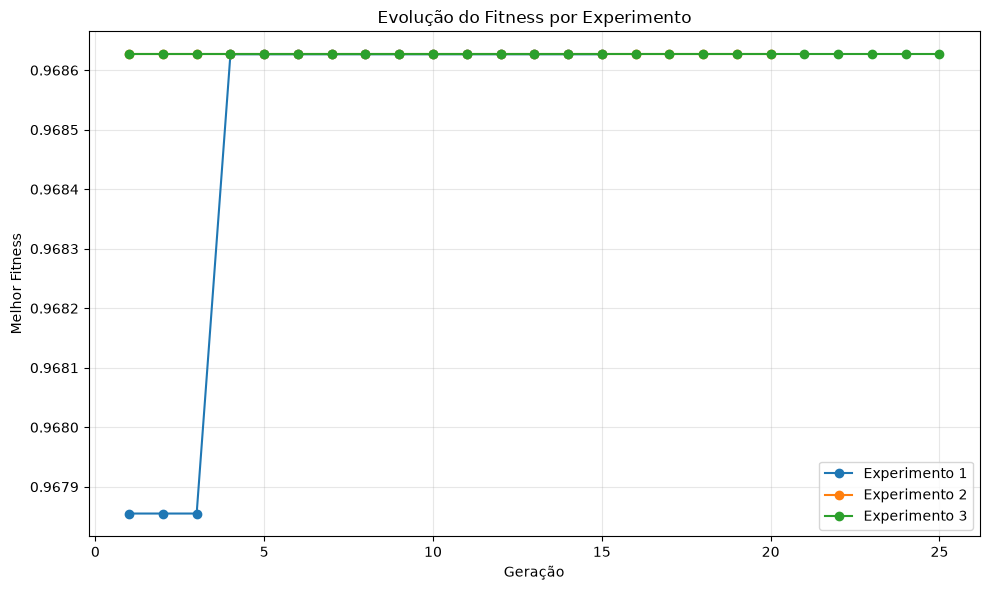

In [72]:
pasta_resultados = Path(
    "/app/results"
)

pasta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

plt.figure(
    figsize=(10, 6)
)

for experimento in experimentos:

    historico_df = pd.DataFrame(
        experimento[
            "historico"
        ]
    )

    plt.plot(
        historico_df["geracao"],
        historico_df[
            "melhor_fitness"
        ],
        marker="o",
        label=experimento["nome"]
    )

plt.xlabel("Geração")

plt.ylabel(
    "Melhor Fitness"
)

plt.title(
    "Evolução do Fitness "
    "por Experimento"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "02_evolucao_fitness_ga.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [73]:
melhor_experimento = max(
    experimentos,
    key=lambda experimento:
        experimento[
            "melhor"
        ]["fitness"]
)

melhor_individuo = (
    melhor_experimento[
        "melhor"
    ]["individuo"]
)

melhores_parametros = (
    decodificar_individuo(
        melhor_individuo
    )
)

print(
    "=== MELHOR EXPERIMENTO ==="
)

print(
    melhor_experimento[
        "nome"
    ]
)

print()

print(
    "Indivíduo:"
)

print(
    melhor_individuo
)

print()

print(
    "Hiperparâmetros:"
)

print(
    melhores_parametros
)

print()

print(
    f"Fitness: "
    f"{melhor_experimento['melhor']['fitness']:.4f}"
)

print(
    f"Recall CV: "
    f"{melhor_experimento['melhor']['recall']:.4f}"
)

print(
    f"F1 CV: "
    f"{melhor_experimento['melhor']['f1']:.4f}"
)

print(
    f"ROC-AUC CV: "
    f"{melhor_experimento['melhor']['roc_auc']:.4f}"
)

=== MELHOR EXPERIMENTO ===
Experimento 1

Indivíduo:
[2, 1, 1]

Hiperparâmetros:
{'C': 0.1, 'class_weight': 'balanced', 'solver': 'liblinear', 'penalty': 'l2'}

Fitness: 0.9686
Recall CV: 0.9588
F1 CV: 0.9674
ROC-AUC CV: 0.9949


## Avaliação final no conjunto de teste

Durante todo o processo de otimização, o conjunto de teste permaneceu isolado.

O Algoritmo Genético utilizou somente os dados de treinamento e validação cruzada para selecionar os melhores hiperparâmetros.

Após concluir a otimização, o melhor indivíduo encontrado será utilizado para treinar o modelo final. Somente neste momento o conjunto de teste será utilizado para medir o desempenho final do modelo.